# Лабораторна робота №2. Подібність текстів

**Мета** — підготувати англомовні тексти, перетворити їх на числові вектори TF‑IDF і порівняти за косинусною подібністю. Той самий метод застосовано до двох наборів даних. Наприкінці є бонусний приклад із Word2Vec.

Результати виконання збережені в ноутбуці. Функції аналізу містяться у файлі `lab2.py`. Команда `python main.py` запускає той самий аналіз із термінала. Інструкція є в `README.md`. Ноутбук перевірено з Python 3.12. Для повторного запуску встановіть залежності командою `python -m pip install -r requirements.txt`, виберіть у Jupyter ядро із цими бібліотеками та виконайте **Restart Kernel and Run All Cells** з каталогу ноутбука. Файл `resources/data.json` входить до роботи. Для виконання комірок доступ до інтернету не потрібен.

[Вихідне завдання](https://github.com/maxvonlancaster/ida-labs/blob/main/assignement-2.ipynb)

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from lab2 import (
    DATA_PATH,
    calculate_tfidf,
    closest_pair,
    embedding_similarity,
    extract_texts_from_file,
    get_texts,
    process_texts,
    train_word2vec,
    visualize_data,
)

%matplotlib inline

## 1. Зчитування текстів із JSON

`json.load()` перетворює JSON на словник Python. За ключем `texts` дістаємо список рядків і зберігаємо їхній порядок. Позиція елемента визначає номер документа на обох осях теплової карти.

In [2]:
texts = extract_texts_from_file(DATA_PATH)
print(f"Зчитано документів: {len(texts)}")
for number, text in enumerate(texts, start=1):
    print(f"{number:2d}. {text}")

Зчитано документів: 10
 1. Oppenheimer, directed by Christopher Nolan, delves into the life of J. Robert Oppenheimer, the theoretical physicist who led the development of the atomic bomb. The film explores his moral and emotional struggles.
 2. Oppenheimer captures the life of the 'father of the atomic bomb' and his internal conflict after the success of the Manhattan Project. The film's complex narrative reflects on the cost of scientific achievement.
 3. In Oppenheimer, Cillian Murphy delivers a riveting performance as the conflicted physicist who grapples with the consequences of his groundbreaking work on the atomic bomb, under the weight of global politics and ethics.
 4. Oppenheimer is a cinematic exploration of ambition, guilt, and responsibility. Through stunning visuals and a thought-provoking story, Nolan brings the life of the brilliant but haunted physicist to the big screen.
 5. Ducks are versatile waterfowl, known for their adaptability in freshwater and coastal habitats.

## 2. Попередня обробка

1. Нормалізуємо Unicode та апострофи, переводимо текст у нижній регістр.
2. Розгортаємо відомі скорочення (`AI`, `NLP`, `e.g.`, `U.S.`) та кілька поширених скорочених форм (`it's`, `don't` тощо). Робимо це до вилучення пунктуації, поки крапки й апострофи ще доступні.
3. Прибираємо присвійне `'s` і виділяємо послідовності англійських літер. Пунктуація, цифри та спеціальні символи відкидаються. Дефіс розділяє слова.
4. Перевіряємо написання перед стемінгом. Виправляємо відомі помилки за словником, а для невідомого слова приймаємо лише єдиний словниковий варіант на відстані однієї правки. Імена з вихідних текстів захищено від автовиправлення.
5. Застосовуємо англійський Snowball Stemmer. Він зводить форми слова до спільної основи, наприклад `networks → network` і `swimming → swim`. Основа може мати незвичний вигляд, як-от `analysis → analysi`.

In [3]:
demo = "NLP & AI, e.g. swiming in 2026! It's about netwroks."
print("До обробки:   ", demo)
print("Після обробки:", process_texts([demo])[0])

texts_processed = process_texts(texts)
print()
for number, text in enumerate(texts_processed, start=1):
    print(f"{number:2d}. {text}")

До обробки:    NLP & AI, e.g. swiming in 2026! It's about netwroks.
Після обробки: natur languag process artifici intellig for exampl swim in it is about network

 1. oppenheim direct by christoph nolan delv into the life of j robert oppenheim the theoret physicist who led the develop of the atom bomb the film explor his moral and emot struggl
 2. oppenheim captur the life of the father of the atom bomb and his intern conflict after the success of the manhattan project the film s complex narrat reflect on the cost of scientif achiev
 3. in oppenheim cillian murphi deliv a rivet perform as the conflict physicist who grappl with the consequ of his groundbreak work on the atom bomb under the weight of global polit and ethic
 4. oppenheim is a cinemat explor of ambit guilt and respons through stun visual and a thought provok stori nolan bring the life of the brilliant but haunt physicist to the big screen
 5. duck are versatil waterfowl known for their adapt in freshwat and coastal habitat

## 3. TF‑IDF і косинусна подібність

Кожен документ стає вектором, координати якого відповідають словам зі словника корпусу. Частота терміна в документі — **TF**. **IDF** зменшує вагу слів, які трапляються в багатьох документах. У scikit‑learn зі згладжуванням використовуються такі формули.

$$operatorname{idf}(t)=1+ln!left(rac{1+n}{1+operatorname{df}(t)}
ight), qquad
w_{t,d}=operatorname{tf}(t,d)cdotoperatorname{idf}(t).$$

Тут $n$ — кількість документів, а $operatorname{df}(t)$ — кількість документів із терміном $t$. Службові слова вилучаємо зі словника TF‑IDF за списком англійських стоп-слів, приведеним до тих самих основ. Далі вектори нормуються за L2. Косинусна подібність дорівнює

$$cos(	heta)=rac{mathbf{x}cdotmathbf{y}}{|mathbf{x}|_2,|mathbf{y}|_2}.$$

Для TF‑IDF ваги невід’ємні, тому оцінки лежать між 0 і 1. Одиниця означає збіг напряму векторів, а нуль для ненульових векторів — відсутність спільних термінів у їхньому представленні. Якщо документ не має жодного терміна після фільтрації, його подібність приймаємо за 0. Матриця симетрична, а на діагоналі для ненульових векторів стоять одиниці.

In [4]:
cosine_matrix = calculate_tfidf(texts_processed)
print(f"Розмір матриці: {cosine_matrix.shape}")
print(np.array2string(cosine_matrix, precision=3, suppress_small=True))

Розмір матриці: (10, 10)
[[1.    0.195 0.154 0.201 0.    0.    0.    0.    0.    0.   ]
 [0.195 1.    0.141 0.06  0.    0.    0.    0.    0.081 0.   ]
 [0.154 0.141 1.    0.06  0.    0.    0.    0.    0.    0.   ]
 [0.201 0.06  0.06  1.    0.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.    1.    0.    0.038 0.    0.    0.   ]
 [0.    0.    0.    0.    0.    1.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.038 0.    1.    0.037 0.039 0.037]
 [0.    0.    0.    0.    0.    0.    0.037 1.    0.116 0.136]
 [0.    0.081 0.    0.    0.    0.    0.039 0.116 1.    0.18 ]
 [0.    0.    0.    0.    0.    0.    0.037 0.136 0.18  1.   ]]


## 4. Теплова карта вихідних текстів

Кожна клітинка показує подібність двох документів. Підписи містять їхні номери і перші чотири слова очищеного тексту. Світліші клітинки мають вищі оцінки. Найближчу пару шукаємо за верхнім трикутником матриці без діагоналі, щоб пропустити порівняння документа із самим собою та врахувати кожну пару один раз.

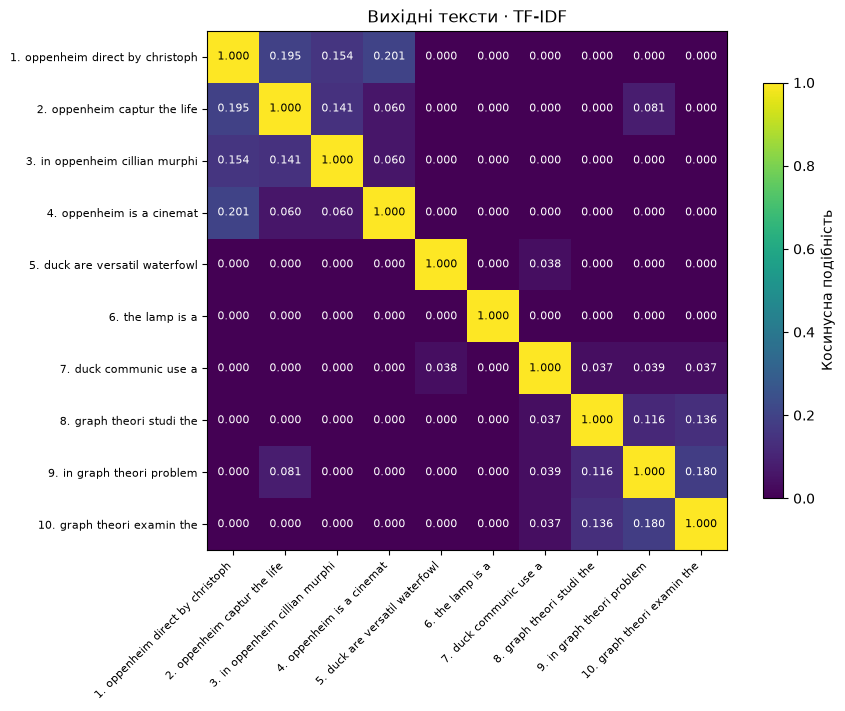

Найподібніша пара: №1 і №4 (косинус = 0.201)
Тексти про качок, №5 і №7: 0.038
Найвища подібність тексту №6 до інших: 0.000


In [5]:
visualize_data(cosine_matrix, texts_processed, "Вихідні тексти · TF-IDF")
plt.show()
first, second, score = closest_pair(cosine_matrix)
print(f"Найподібніша пара: №{first} і №{second} (косинус = {score:.3f})")
print(f"Тексти про качок, №5 і №7: {cosine_matrix[4, 6]:.3f}")
print(f"Найвища подібність тексту №6 до інших: {np.delete(cosine_matrix[5], 5).max():.3f}")

Тексти №1–4 описують фільм *Oppenheimer*, №5 і №7 — качок, №8–10 — теорію графів. Матриця відображає спільність лексики на кшталт `atomic bomb` або `graph theory`. Тексти про качок мають спільну тему, але один зосереджений на середовищі та плаванні, другий — на звуках і поведінці. Через різну лексику їхня оцінка може бути слабкою. Текст №6 поєднує лампу, тостер та інші сторонні образи, тому має слабкий збіг з рештою корпусу.

## 5. Аналіз власних текстів

Шість коротких англомовних текстів написано для цієї роботи. Вони утворюють три тематичні пари — обробка мови, плавання качок і пошук шляху в графі. Скорочення `NLP` і `AI` та помилки `swiming` і `netwroks` перевіряють етап очищення. TF‑IDF навчаємо на цих шести документах, тож показники IDF відображають частоти саме в цьому наборі.

1. NLP systems use AI to classify customer messages and detect sentiment.
   natur languag process system use artifici intellig to classifi custom messag and detect sentiment
2. Natural language processing uses artificial intelligence to classify customer messages by sentiment.
   natur languag process use artifici intellig to classifi custom messag by sentiment
3. Ducks are swiming in ponds. Their webbed feet help them swim in shallow water.
   duck are swim in pond their web feet help them swim in shallow water
4. Ducks swim in shallow water and use webbed feet to move across ponds.
   duck swim in shallow water and use web feet to move across pond
5. Graph algorithms find the shortest path between nodes in transportation netwroks.
   graph algorithm find the shortest path between node in transport network
6. In transportation networks, graph algorithms compute the shortest path between nodes.
   in transport network graph algorithm comput the shortest path between node

Матриця поді

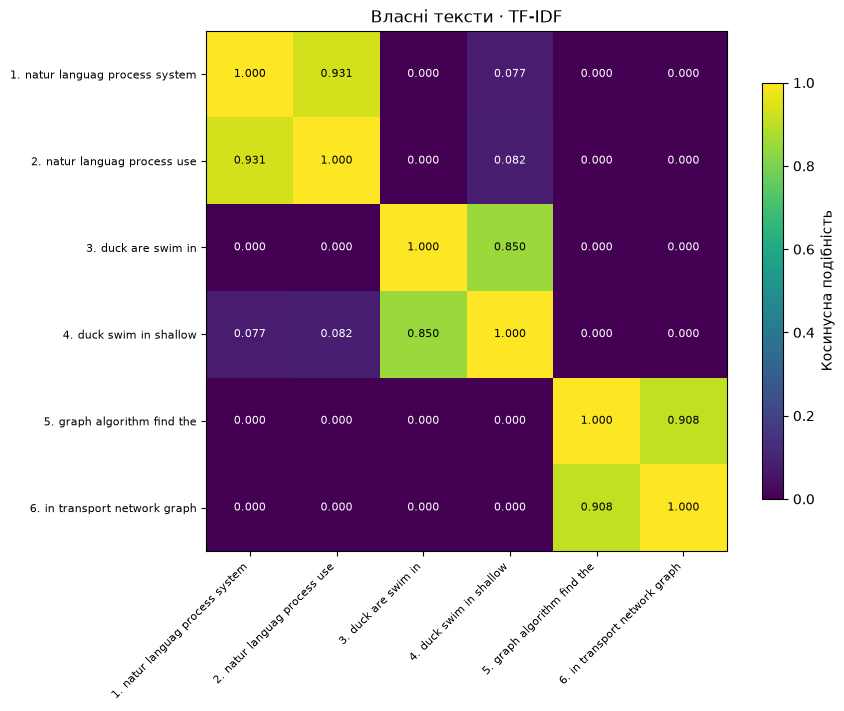

Пара №1 і №2: 0.931
Пара №3 і №4: 0.850
Пара №5 і №6: 0.908


In [6]:
own_texts = get_texts()
own_processed = process_texts(own_texts)
own_cosine_matrix = calculate_tfidf(own_processed)

for number, (text, processed) in enumerate(zip(own_texts, own_processed), start=1):
    print(f"{number}. {text}\n   {processed}")
print("\nМатриця подібності:")
print(np.array2string(own_cosine_matrix, precision=3, suppress_small=True))
visualize_data(own_cosine_matrix, own_processed, "Власні тексти · TF-IDF")
plt.show()
for row, column in [(0, 1), (2, 3), (4, 5)]:
    print(f"Пара №{row + 1} і №{column + 1}: {own_cosine_matrix[row, column]:.3f}")

## Бонус. Word2Vec зі зважуванням за TF‑IDF

Навчаємо Word2Vec у режимі skip‑gram на об’єднанні двох корпусів із 16 документів. Модель отримує послідовності нормалізованих слів і навчається передбачати сусідні слова. Для кожного документа усереднюємо вектори слів з вагами TF‑IDF його корпусу. Слово може впливати на подібність навіть за відсутності буквального збігу, якщо його вектор близький до вектора іншого слова.

$$mathbf{d}=rac{sum_t w_{t,d},mathbf{v}_t}{sum_t w_{t,d}}.$$

Косинус для щільних векторів може бути від’ємним, тому шкала бонусних карт охоплює проміжок від −1 до 1. Модель навчено на дуже малому корпусі, тому оцінки ілюструють метод. Щоб визначити, чи покращує Word2Vec якість групування, потрібні більший корпус для навчання і незалежні еталонні оцінки подібності.

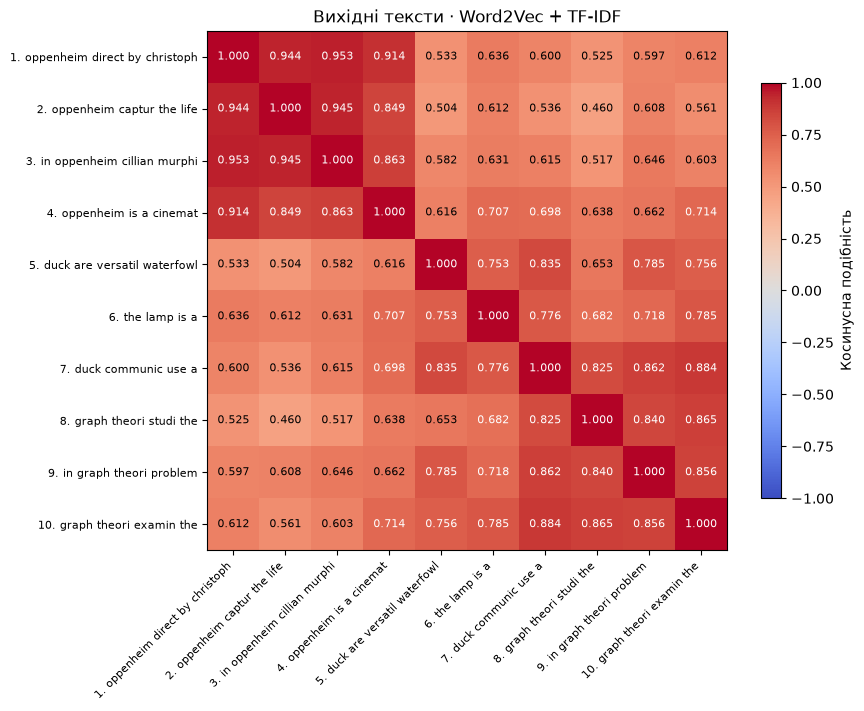

Вихідні тексти, найближча пара: №1 і №3 (косинус = 0.953)


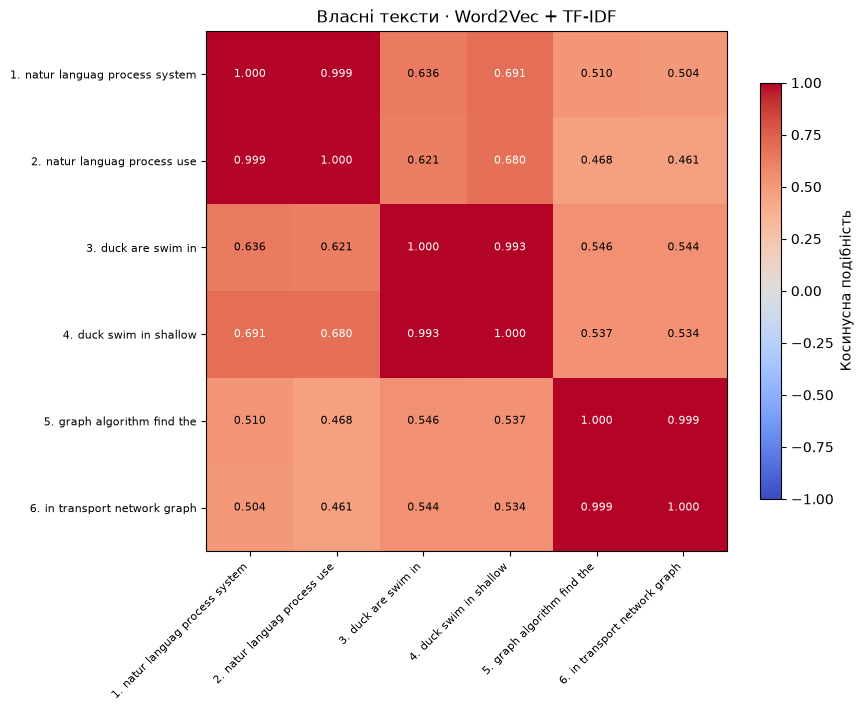

Власні тексти, найближча пара: №5 і №6 (косинус = 0.999)


In [7]:
word2vec = train_word2vec(texts_processed + own_processed)

for corpus_name, corpus in [("Вихідні тексти", texts_processed), ("Власні тексти", own_processed)]:
    embedding_matrix = embedding_similarity(corpus, word2vec)
    visualize_data(embedding_matrix, corpus, f"{corpus_name} · Word2Vec + TF-IDF", signed=True)
    plt.show()
    first, second, score = closest_pair(embedding_matrix)
    print(f"{corpus_name}, найближча пара: №{first} і №{second} (косинус = {score:.3f})")

## Висновок

TF‑IDF показує, наскільки збігається важлива для корпусу лексика. На власних прикладах тематичні пари містять багато спільних термінів після нормалізації, тож їх видно як три пари світлих клітинок поза діагоналлю. Вихідний приклад про качок показує, що два тексти можуть описувати одну тему й отримати невелику оцінку, якщо їхні слова переважно різні. На бонусній карті власних текстів навіть пари з різних тем мають помітну подібність. Це видно за клітинками між тематичними блоками. Високі оцінки Word2Vec в цьому запуску самі по собі не означають кращого групування.